# Introduction - Olympics Data Exploratory Data Analysis
With the Olympics featuring almost 400 sports events and 10K+ athletes, a massive amount of data is produced during each Olympic event. Our exploratory data analysis of the Olympics will transform the raw dataset into clear insights for journalists to refer to.
The exploration below seeks to answer some questions journalists may have. How has performance from countries changed over time? Time series analysis can reveal if any countries consistently perform well, or if any are rising and declining in performance. Who are the top Olympians? Exploration and visualization will describe if some have higher amounts of gold/silver/bronze than others.
Our thorough analysis on these topics will allow sports journalists to quickly publish stories that contain accurate information on these trending events and Olympians.

# Data and Library Installing

In [1]:
# Load all required packages
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import olympics dataset
olympics = pd.read_csv('olympics.csv')

#### Libraries Installed:
Pandas (import pandas as pd): Pandas was used to load and organize the Olympics dataset into a table format. It allows us to clean, analyze, and summarize the data.
Seaborn (import seaborn as sns): Seaborn was used to create statistical graphs that help identify patterns and trends in the Olympics dataset. It makes comparing athlete performance and medal counts easier.
Matplotlib Pyplot (import matplotlib.pyplot as plt): Matplotlib was used to create and customize graphs and charts for the project. It allows us to add titles, labels, and other formatting to make the visualizations easier to understand.
Reading the Dataset (olympics = pd.read_csv(‘olympics.csv’)): This code loads the Olympics CSV file into a Pandas DataFrame named ‘olympics’. This allows us to access and analyze the data throughout the project.


# Data Preparation

### Comprehensive explanation of source data
Olympics is a basic dataset that details medal results ranging from Athens 1896 to Rio 2016. This dataset was created in May 2018 by Randi Griffin, [kaggle.com](https://www.kaggle.com/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results/) who sourced the information from [sportsreference.com](http://www.sports-reference.com/).
This dataset was then consolidated into a convenient format for data analysis by Jon Harmon.

Randi Griffin's inspiration for the dataset sources from the  'opportunity to ask questions about how the Olympics have evolved over time, including questions about the participation and performance of women, different nations, and different sports and events'.

## Missing Values

In [2]:
#check for missing values
# 1. Identify missing values in each column
olympics.isna().sum()

id             0
name           0
sex            0
age         9474
height     60171
weight     62875
team           0
noc            0
games          0
year           0
season         0
city           0
sport          0
event          0
medal     231333
dtype: int64

### Medal column encoding

In [3]:
#Encode medal column
medal_mapping = {
    'Gold': 3,
    'Silver': 2,
    'Bronze': 1,
    'NA': 0
}

# 2. Create the new medal column 
olympics['medal_encoded'] = olympics['medal'].map(medal_mapping).fillna(0).astype(int)


#### Data importing and cleaning documentation
The Olympics dataset was imported using Pandas, and we checked for missing values in each column using ‘olympucs.isna().sum()’ to identify the incomplete rows. We then encoded the medal column by assigning gold a value of 3, silver a value of 2, bronze a value of 1, and missing medals a value of 0, making it easier to compare medal results numerically. When calculating top 5 teams and olympians, this new medal column adds weight to a higher achivement of gold and silver compared to bronze. This was calculated and placed in an enirely new column to preserve the origninal data.  Missing values were found in 'age', 'height' and 'weight' columns. A decison was made not to impute these values as height and weight are very important in some sports and should not be estimated. These steps help prepare the dataset for accurate analysis and visualizations.

### Final Cleaned dataset

In [4]:
#Show final cleaned dataset
olympics.head()

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal,medal_encoded
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,3
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,0


# Key Variable Summarization and Summary Statistics

In [5]:
#Show summary statistics
olympics.describe(include='all')

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal,medal_encoded
count,271116.000000,271116,271116,261642.000000,210945.000000,208241.000000,271116,271116,271116,271116.000000,271116,271116,271116,271116,39783,271116.000000
unique,NaN,134731,2,NaN,NaN,NaN,1184,230,51,NaN,2,42,66,765,3,NaN
top,NaN,Robert Tait McKenzie,M,NaN,NaN,NaN,United States,USA,2000 Summer,NaN,Summer,London,Athletics,Football Men's Football,Gold,NaN
freq,NaN,58,196594,NaN,NaN,NaN,17847,18853,13821,NaN,222552,22426,38624,5733,13372,NaN
mean,68248.954396,NaN,NaN,25.556898,175.338970,70.702393,NaN,NaN,NaN,1978.378480,NaN,NaN,NaN,NaN,NaN,0.293760
std,39022.286345,NaN,NaN,6.393561,10.518462,14.348020,NaN,NaN,NaN,29.877632,NaN,NaN,NaN,NaN,NaN,0.774697
min,1.000000,NaN,NaN,10.000000,127.000000,25.000000,NaN,NaN,NaN,1896.000000,NaN,NaN,NaN,NaN,NaN,0.000000
25%,34643.000000,NaN,NaN,21.000000,168.000000,60.000000,NaN,NaN,NaN,1960.000000,NaN,NaN,NaN,NaN,NaN,0.000000
50%,68205.000000,NaN,NaN,24.000000,175.000000,70.000000,NaN,NaN,NaN,1988.000000,NaN,NaN,NaN,NaN,NaN,0.000000
75%,102097.250000,NaN,NaN,28.000000,183.000000,79.000000,NaN,NaN,NaN,2002.000000,NaN,NaN,NaN,NaN,NaN,0.000000


#### Summary Statistics Findings and Key Variable Summarization
Each row in this dataset belongs to one athlete and one event. It details a unique id for each athlete, their sex, age, height, team, date, location and what sport and event was played.
One of the most important variables in this dataset is the 'medal' column. It shows what medal the athlete won, or if no medal was won for the event. It features 4 values, 'Gold', 'Silver', 'Bronze' and 'NA'. Its important to note that the 'NA' values in this column mean that the athlete did not win a medal. It does not represent missing data.

Other important variables are 'id' which is an unique numerical value assigned to each olympian. 'name' is the athlete's name. This is a character class that includes the athelets first and last name in one cell. 'noc' is a 3 letter code of the National Olympic Committee represented in the particular event.

The summary statistics calculated in the cell above show that years in the dataset span 1896-2016. There are 134,731 olympians with an average age of 25. The youngest is 10 and oldest is 97.
There are 1184 teams and 230 noc's. The dataset covers 765 events, and 51 games.
 

In [6]:
# create male olympics dataframe 
olympics_male = olympics[(olympics['sex'] == 'M') ]
olympics_male.head()

# create female olympics dataframe
olympics_female = olympics[(olympics['sex'] == 'F') ]
olympics_female.head()

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal,medal_encoded
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,0
5,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,"Speed Skating Women's 1,000 metres",NaN,0
6,5,Christine Jacoba Aaftink,F,25.0,185.0,82.0,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,Speed Skating Women's 500 metres,NaN,0
7,5,Christine Jacoba Aaftink,F,25.0,185.0,82.0,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,"Speed Skating Women's 1,000 metres",NaN,0
8,5,Christine Jacoba Aaftink,F,27.0,185.0,82.0,Netherlands,NED,1994 Winter,1994,Winter,Lillehammer,Speed Skating,Speed Skating Women's 500 metres,NaN,0


## Finding the top olympians for each sex

In [7]:
#===================== TOP 5 MALE ATHLETES ===========================
# Group by id and name, then calculate both metrics
grouped = olympics_male.groupby(['id', 'name']).agg( 
    total_score=('medal_encoded', 'sum'), # weighted medal score 
    medal_count=('medal', 'count') # total number of medals
)

#Get the top 5 based on the encoded medal score
top_5_olympians = grouped.nlargest(5, 'total_score').reset_index()

print("Top 5 Male Olympians")
print(top_5_olympians)

#===================== TOP 5 FEMALE ATHLETES =========================
# Group by id and name, then calculate both metrics
grouped = olympics_female.groupby(['id', 'name']).agg( 
    total_score=('medal_encoded', 'sum'), # weighted medal score 
    medal_count=('medal', 'count') # total number of medals
)

#Get the top 5 based on the encoded medal score
top_5_olympiansfemale = grouped.nlargest(5, 'total_score').reset_index()

print("Top 5 Female Olympians")
print(top_5_olympiansfemale)

Top 5 Male Olympians
      id                          name  total_score  medal_count
0  94406       Michael Fred Phelps, II           77           28
1   4198  Nikolay Yefimovich Andrianov           34           15
2  11951           Ole Einar Bjrndalen           33           13
3  87390          Paavo Johannes Nurmi           33           12
4  57998                    Sawao Kato           31           12
Top 5 Female Olympians
       id                                             name  total_score  \
0   67046               Larysa Semenivna Latynina (Diriy-)           41   
1   35550                           Birgit Fischer-Schmidt           32   
2  119922  Jennifer Elisabeth "Jenny" Thompson (-Cumpelik)           31   
3   18826                           Vra slavsk (-Odloilov)           29   
4  129726                            Isabelle Regina Werth           26   

   medal_count  
0           18  
1           12  
2           12  
3           11  
4           10  


#### Top olympian findings
The table shows the top 5 male olympians. 'total_score' is their total weighted medal score and 'medal_count' is the total amount of medals the athlete won.
The top male Olympian is Michael Fred Phelps II, who leads with a weighted medal score of 77 and 28 total medals. Among female Olympians, Larysa Semenivna Latynina ranks first with a weighted score of 41 and 18 total medals, followed by Birgit Fischer-Schmidt with 32 points and 12 medals. Overall, these findings show that Phelps leads both groups in total medals, while Latynina is the highest ranked female Olympian.

# Top Olympian Bar Charts

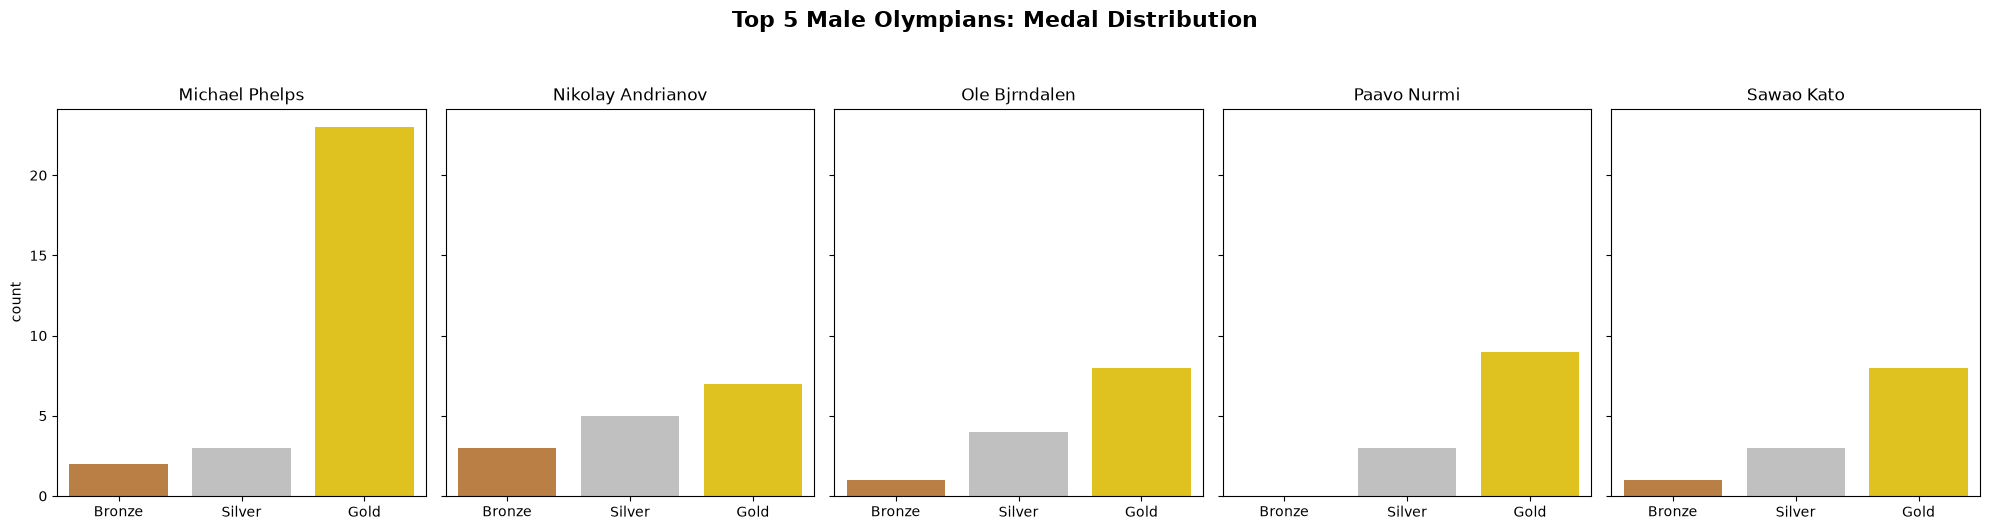

In [8]:
#=======================================================================
#              TOP 5 MALE ATHETES
#=======================================================================

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)

medal_order = ['Bronze', 'Silver', 'Gold']

# ================= MICHAEL PHELPS =================
olympics_michael = olympics[olympics['id'] == 94406]
sns.countplot(data=olympics_michael, x='medal', hue='medal', legend=False, ax=axes[0],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[0].set_title('Michael Phelps')
axes[0].set_xlabel('')

# ================= NIKOLAY ANDRIANOV =================
olympics_andrianov = olympics[olympics['id'] == 4198]
sns.countplot(data=olympics_andrianov, x='medal', hue='medal', legend=False, ax=axes[1],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[1].set_title('Nikolay Andrianov')
axes[1].set_xlabel('')

# ================= OLE Bjrndalen =================
olympics_ole = olympics[olympics['id'] == 11951]
sns.countplot(data=olympics_ole, x='medal', hue='medal', legend=False, ax=axes[2],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[2].set_title('Ole Bjrndalen')
axes[2].set_xlabel('')

# ================= PAAVO NURMI =================
olympics_paavo = olympics[olympics['id'] == 87390]
sns.countplot(data=olympics_paavo, x='medal', hue='medal', legend=False, ax=axes[3],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[3].set_title('Paavo Nurmi')
axes[3].set_xlabel('')

# ================= SAWAO KATO =================
olympics_sawao = olympics[olympics['id'] == 57998]
sns.countplot(data=olympics_sawao, x='medal', hue='medal', legend=False, ax=axes[4],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[4].set_title('Sawao Kato')
axes[4].set_xlabel('')

plt.suptitle('Top 5 Male Olympians: Medal Distribution', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

#### Top male olympian findings
The bar chart shows that Michael Phelps stands out among the top five male Olympians, with 23 gold medals, 3 silver medals, and 2 bronze medals. Nikolay Andrianov and Ole Einar Bjorndalen also performed well, earning 7 and 4 gold medals, while Paavo Nurmi earned 9 gold medals and Sawao Kato earned 8. Overall, Michael Phelps leads by a significant margin in gold medals and total Olympic medals. This chart uncovers the details that made the athlete become the 'top 5'. It shows the distrubution of gold, silver, and bronze medals the olympian has acomplished.


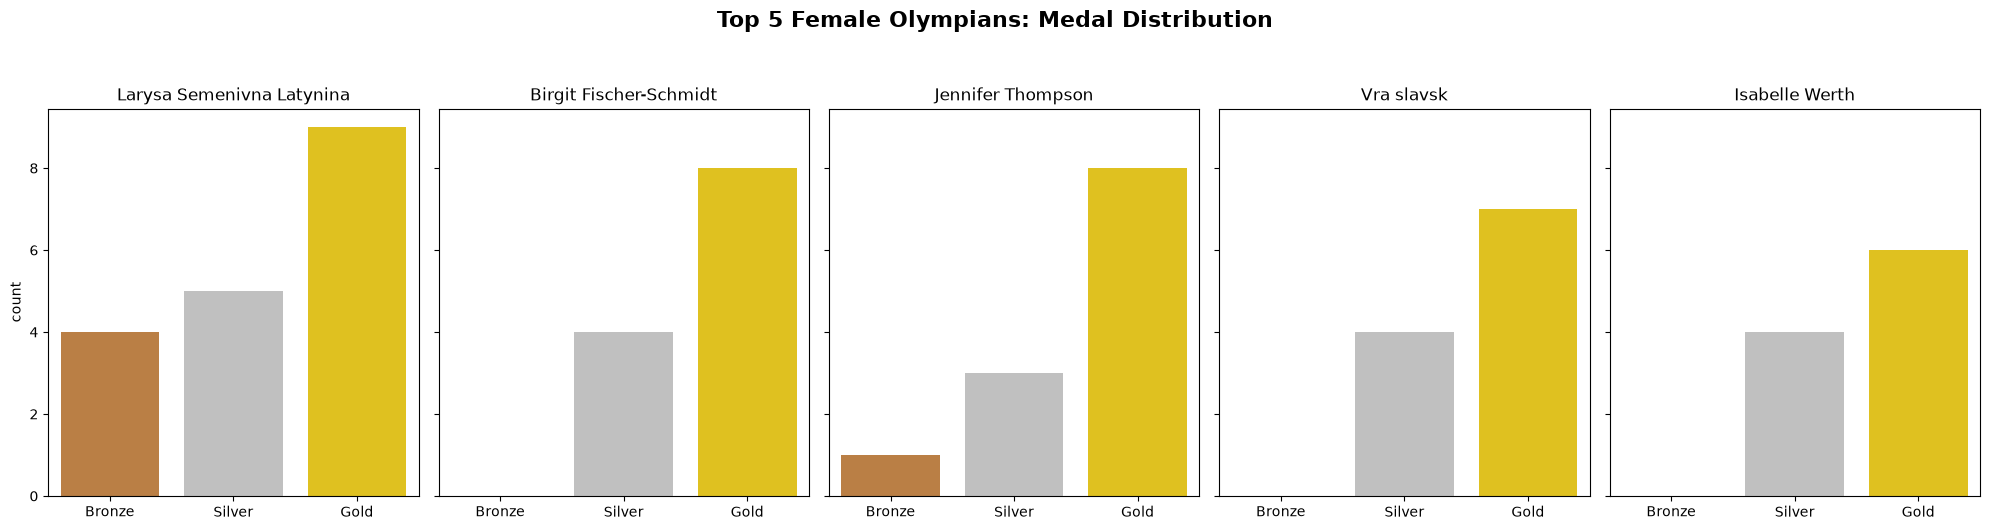

In [9]:
#=======================================================================
#              TOP 5 FEMALE ATHETES
#=======================================================================

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)

# ================= LARYSA LATYNINA =================
olympics_larysa = olympics[olympics['id'] == 67046]
sns.countplot(data=olympics_larysa, x='medal', hue='medal', legend=False, ax=axes[0],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[0].set_title('Larysa Semenivna Latynina')
axes[0].set_xlabel('')

# ================= BIRGIT FISCHER-SCHMIDT =================
olympics_birgit = olympics[olympics['id'] == 35550]
sns.countplot(data=olympics_birgit, x='medal', hue='medal', legend=False, ax=axes[1],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[1].set_title('Birgit Fischer-Schmidt')
axes[1].set_xlabel('')

# ================= JENNIFER THOMPSON =================
olympics_jennifer= olympics[olympics['id'] == 119922]
sns.countplot(data=olympics_jennifer, x='medal', hue='medal', legend=False, ax=axes[2],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[2].set_title('Jennifer Thompson')
axes[2].set_xlabel('')

# ================= VRA SLAVSK =================
olympics_vra = olympics[olympics['id'] == 18826 ]
sns.countplot(data=olympics_vra, x='medal', hue='medal', legend=False, ax=axes[3],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[3].set_title('Vra slavsk')
axes[3].set_xlabel('')


# ================= ISABELLE WERTH =================
olympics_isabelle = olympics[olympics['id'] == 129726]
sns.countplot(data=olympics_isabelle, x='medal', legend=False, hue='medal', ax=axes[4],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[4].set_title('Isabelle Werth')
axes[4].set_xlabel('')

plt.suptitle('Top 5 Female Olympians: Medal Distribution', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


#### Top female olympian findings
The bar chart shows Larysa Semenivna Latynina earned the most medals, with 9 gold, 5 silver, and 4 bronze medals. Birgit Fischer-Schmidt also performed exceptionally well, earning 8 gold and 4 silver medals, while Jennifer Thompson won 8 gold medals along with 3 silver and 1 bronze medal. Overall, the chart highlights the impressive achievements of these top female Olympians, with gold medals being the most common medal type among them.


# Extracting top countries
The code below lists the top 5 countries based on a weighted medal score. Then the dataset is filtered to show entries cumulative running medal totals

In [10]:
# ==========================================
# TOP MALE TEAMS
# =========================================

# find total medals and medal score
grouped_countriesmale = olympics_male.groupby(['noc', 'team']).agg(
    total_score=('medal_encoded', 'sum'),
    medal_count=('medal', 'count')
)

# List the top 5 countries 
top_5_countriesmale = grouped_countriesmale.nlargest(5, 'total_score')

print("Top 5 Male Teams")
print(top_5_countriesmale)

#Filter the dataset to only show rows from the top country list
top_5_resetmale = top_5_countriesmale.reset_index()
top_noc_listmale = top_5_resetmale['noc'].unique()
filtered_dfmale = olympics_male[olympics_male['noc'].isin(top_noc_listmale)]

#filtered date with medals over time
medals_matrixmale = filtered_dfmale.pivot_table(
    index='year', 
    columns='noc', 
    values='medal', 
    aggfunc='count', 
    fill_value=0
)

#Calculate running total of medals won over time
cumulative_medalsmale = medals_matrixmale.cumsum(axis=0)




#==============================================
# TOP FEMALE TEAMS
#============================================

# find total medals and medal score
grouped_countriesfemale = olympics_female.groupby(['noc', 'team']).agg(
    total_score=('medal_encoded', 'sum'),
    medal_count=('medal', 'count')
)

# List the top 5 countries 
top_5_countriesfemale = grouped_countriesfemale.nlargest(5, 'total_score')

print("Top 5 Female Teams")
print(top_5_countriesfemale)

#Filter the dataset to only show rows from the top country list
top_5_resetfemale = top_5_countriesfemale.reset_index()
top_noc_listfemale = top_5_resetfemale['noc'].unique()
filtered_dffemale = olympics_female[olympics_female['noc'].isin(top_noc_listfemale)]

#filtered date with medals over time
medals_matrixfemale = filtered_dffemale.pivot_table(
    index='year', 
    columns='noc', 
    values='medal', 
    aggfunc='count', 
    fill_value=0
)

#Calculate running total of medals won over time
cumulative_medalsfemale = medals_matrixfemale.cumsum(axis=0)


Top 5 Male Teams
                   total_score  medal_count
noc team                                   
USA United States         7742         3463
URS Soviet Union          3842         1784
GER Germany               2688         1327
ITA Italy                 2688         1311
GBR Great Britain         2598         1293
Top 5 Female Teams
                   total_score  medal_count
noc team                                   
USA United States         3937         1756
URS Soviet Union          1441          667
GER Germany               1281          657
CHN China                 1208          600
RUS Russia                1118          533


#### Top Country/Team Findings
The top five male countries are the United States, Soviet Union, Germany, Italy, and Great Britain, with the United States leading by a significant margin with 3,463 medals and a weighted medal score of 7,742. For female teams, the top five are the United States, Soviet Union, Germany, China, and Russia, with the United States also ranking first with 1,756 medals and a weighted score of 3,937. An interesting finding is that the United States leads both categories, and its weighted medal score is much higher than its total medal count, showing that the scoring system gives additional value to certain medals. 

# Top Countries Bar Charts

Text(0.5, 0, '')

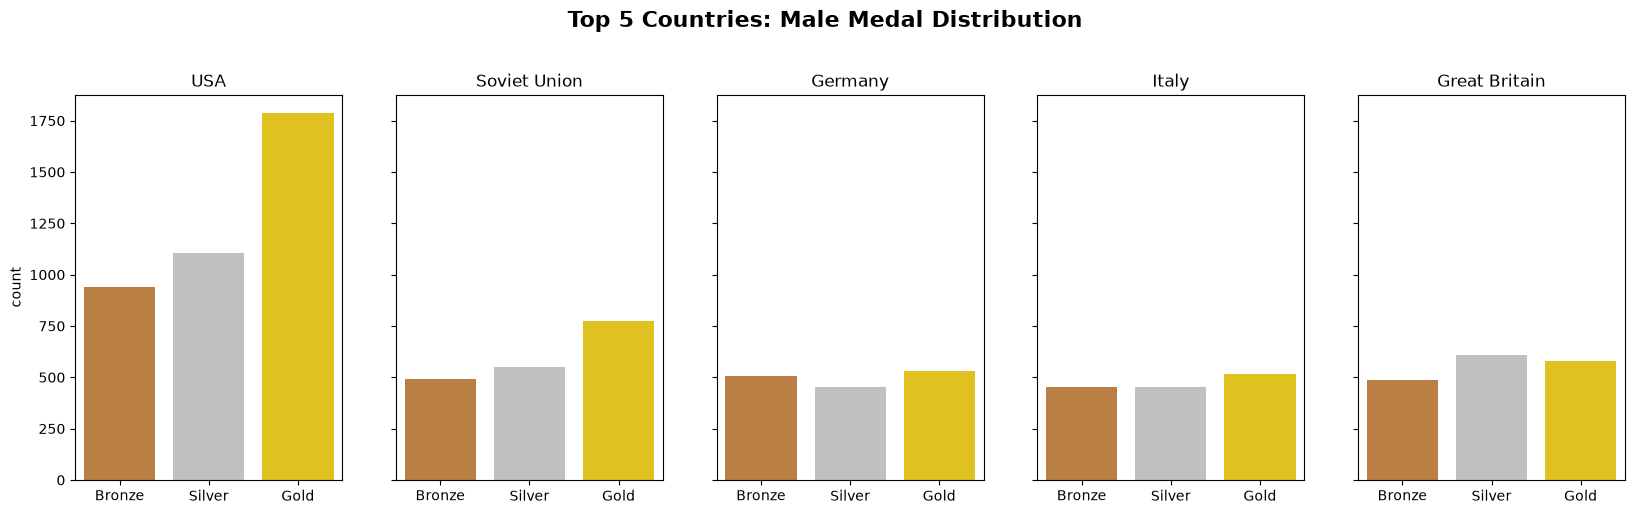

In [14]:
# ==========================================
# TOP MALE COUNTRIES
# =========================================

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)

medal_order = ['Bronze', 'Silver', 'Gold']

# ================= United States =================
male_olympics_USA = olympics_male[olympics_male['noc'] == 'USA']
sns.countplot(data=male_olympics_USA, x='medal', hue='medal', legend=False, ax=axes[0],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[0].set_title('USA')
axes[0].set_xlabel('')

# ================= Soviet Union =================
male_olympics_USR = olympics_male[olympics_male['noc'] == 'URS']
sns.countplot(data=male_olympics_USR, x='medal', hue='medal', legend=False, ax=axes[1],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[1].set_title('Soviet Union')
axes[1].set_xlabel('')

# ================= Germany =================
male_olympics_GER = olympics_male[olympics_male['noc'] == 'GER']
sns.countplot(data=male_olympics_GER, x='medal', hue='medal', legend=False, ax=axes[2],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[2].set_title('Germany')
axes[2].set_xlabel('')

# ================= Italy =================
male_olympics_ITA = olympics_male[olympics_male['noc'] == 'ITA']
sns.countplot(data=male_olympics_ITA, x='medal', hue='medal', legend=False, ax=axes[3],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[3].set_title('Italy')
axes[3].set_xlabel('')

# ================= Great Britain =================
male_olympics_GBR = olympics_male[olympics_male['noc'] == 'GBR']
sns.countplot(data=male_olympics_GBR, x='medal', hue='medal', legend=False, ax=axes[4],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
plt.suptitle('Top 5 Countries: Male Medal Distribution', fontsize=16, fontweight='bold', y=1.05)
axes[4].set_title('Great Britain')
axes[4].set_xlabel('')

These bar plots reveal USA's high amount of gold medal achievements. They appear to have the highest amount of gold medals, as well as a higher ratio of gold compared to silver and bronze. Other countries like Italy have a more equal ration to gold, silver, and bronze.

Text(0.5, 0, '')

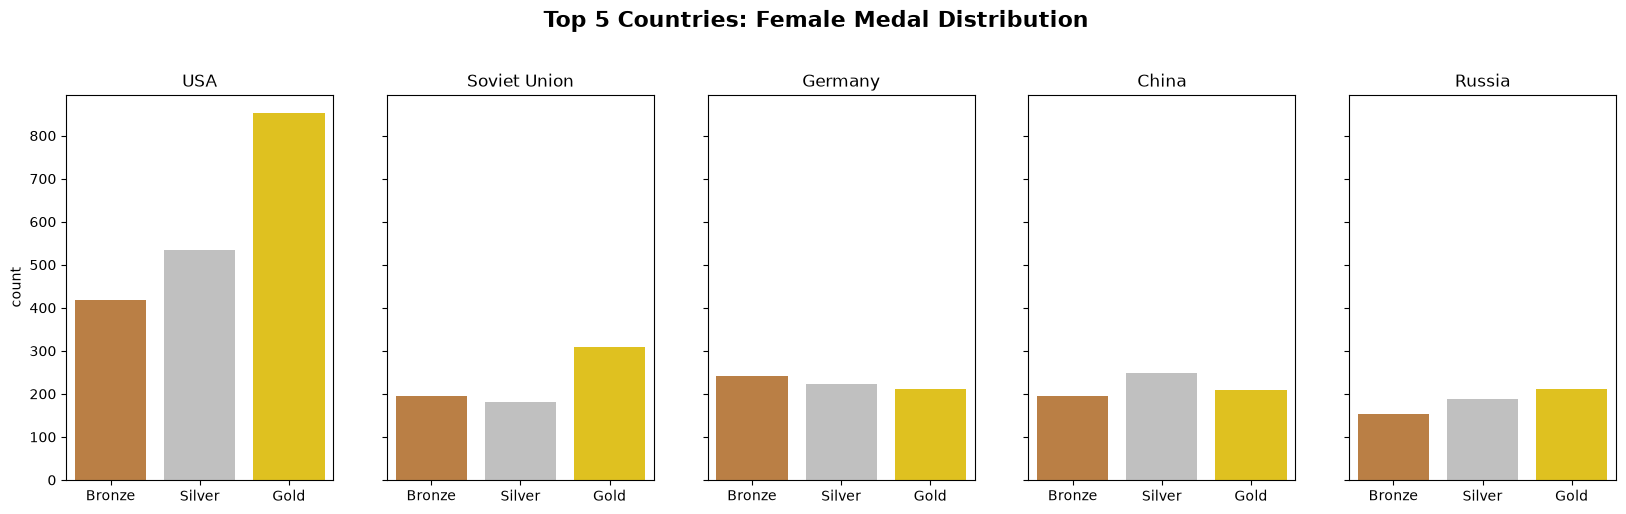

In [15]:
# ==========================================
# TOP FEMALE COUNTRIES
# =========================================

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)

medal_order = ['Bronze', 'Silver', 'Gold']

# ================= United States =================
female_olympics_USA = olympics_female[olympics_female['noc'] == 'USA']
sns.countplot(data=female_olympics_USA, x='medal', hue='medal', legend=False, ax=axes[0],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[0].set_title('USA')
axes[0].set_xlabel('')

# ================= Soviet Union =================
female_olympics_USR = olympics_female[olympics_female['noc'] == 'URS']
sns.countplot(data=female_olympics_USR, x='medal', hue='medal', legend=False, ax=axes[1],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[1].set_title('Soviet Union')
axes[1].set_xlabel('')

# ================= Germany =================
female_olympics_GER = olympics_female[olympics_female['noc'] == 'GER']
sns.countplot(data=female_olympics_GER, x='medal', hue='medal', legend=False, ax=axes[2],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[2].set_title('Germany')
axes[2].set_xlabel('')

# ================= China =================
female_olympics_CHN = olympics_female[olympics_female['noc'] == 'CHN']
sns.countplot(data=female_olympics_CHN, x='medal', hue='medal', legend=False, ax=axes[3],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
axes[3].set_title('China')
axes[3].set_xlabel('')

# ================= Russia =================
female_olympics_RUS = olympics_female[olympics_female['noc'] == 'RUS']
sns.countplot(data=female_olympics_RUS, x='medal', hue='medal', legend=False, ax=axes[4],
             order=medal_order, hue_order=medal_order, palette=['#cd7f32', '#c0c0c0', '#ffd700'])
plt.suptitle('Top 5 Countries: Female Medal Distribution', fontsize=16, fontweight='bold', y=1.05)
axes[4].set_title('Russia')
axes[4].set_xlabel('')

#### Top country findings
These bar plots reveal USA's high amount of gold medal achievements for female teams as well. They appear to have the highest amount of gold medals, as well as a higher ratio of gold compared to silver and bronze. 

# Olympic Team Progression Charts - Male and Female

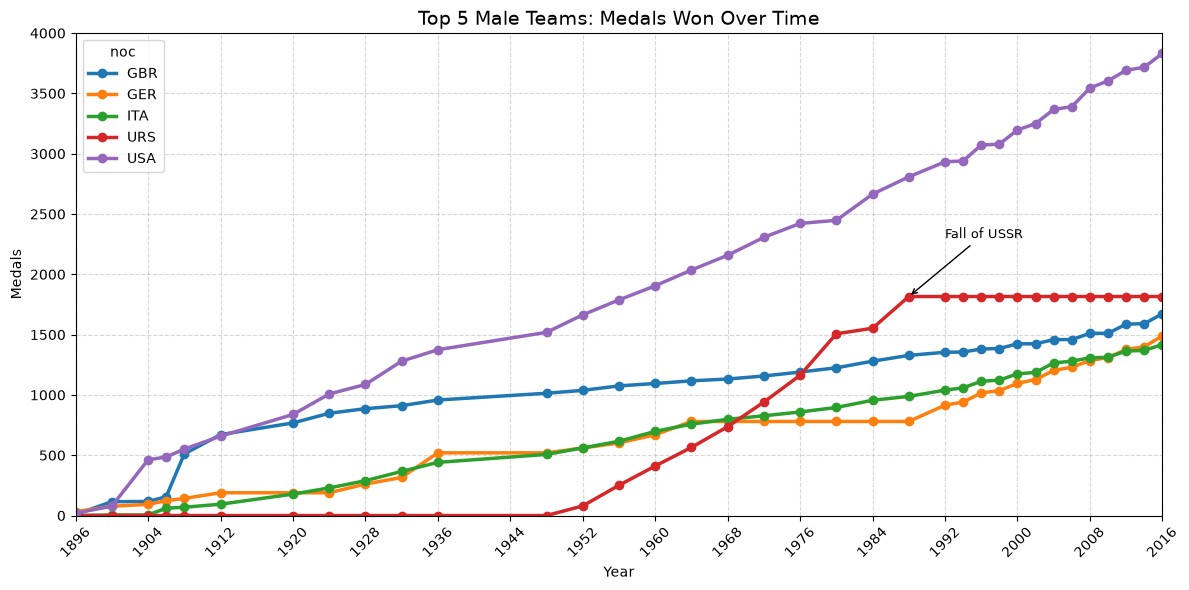

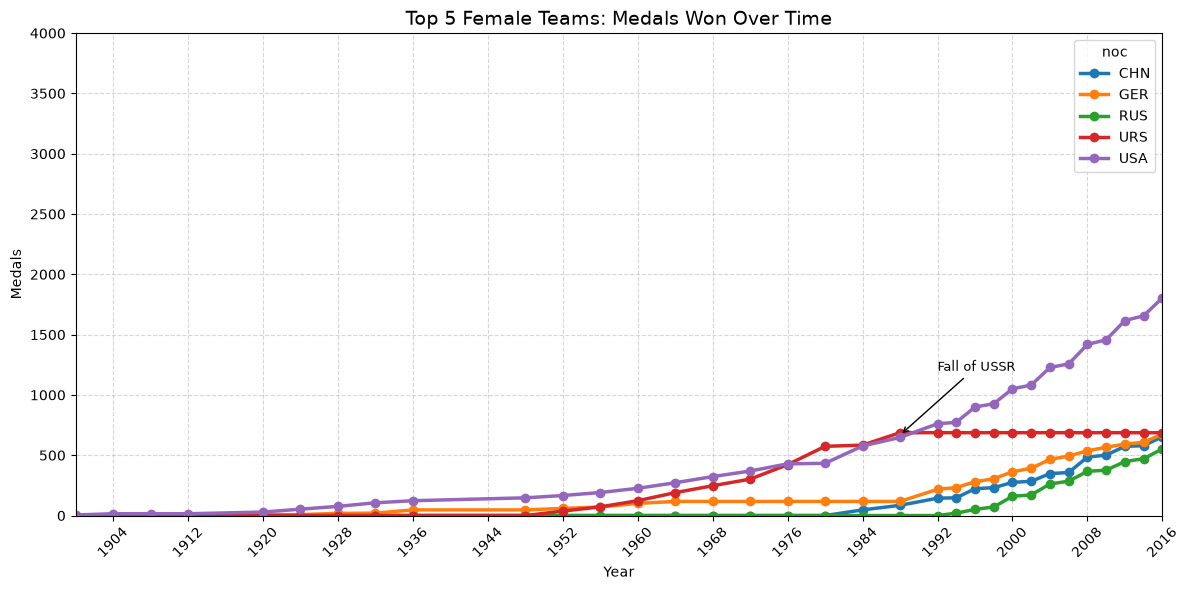

In [13]:
#=====================================================
# MALE LINE PLOT
#=======================================================

#Create line chart
plt.figure(figsize=(12, 6))
for noc in cumulative_medalsmale:
    plt.plot(cumulative_medalsmale.index, cumulative_medalsmale[noc], marker='o',       
        linewidth=2.5, label=noc)
plt.xlabel('Year')
plt.ylabel('Medals')
plt.legend(title='noc')
plt.title('Top 5 Male Teams: Medals Won Over Time', fontsize=14)
plt.xticks(range(1896, 2024, 8), rotation=45)
plt.grid(visible=True, linestyle='--', alpha=0.5)
plt.xlim(cumulative_medalsmale.index.min(), cumulative_medalsmale.index.max())
plt.ylim([0, 4000])
#Just an interesting way to use the arrow
plt.annotate('Fall of USSR',
             xy=(1988, 1815), xytext=(1992, 2300),
             arrowprops=dict(arrowstyle='->', color='black'),
             fontsize=9)
plt.tight_layout()
plt.show()

#=====================================================
# FEMALE LINE PLOT
#=======================================================

#Create line chart
plt.figure(figsize=(12, 6))
for noc in cumulative_medalsfemale:
    plt.plot(cumulative_medalsfemale.index, cumulative_medalsfemale[noc], marker='o',       
        linewidth=2.5, label=noc)
plt.xlabel('Year')
plt.ylabel('Medals')
plt.legend(title='noc')
plt.title('Top 5 Female Teams: Medals Won Over Time', fontsize=14)
plt.xticks(range(1896, 2024, 8), rotation=45)
plt.grid(visible=True, linestyle='--', alpha=0.5)
plt.xlim(cumulative_medalsfemale.index.min(), cumulative_medalsfemale.index.max())
plt.ylim([0, 4000])
plt.annotate('Fall of USSR',
             xy=(1988, 667), xytext=(1992, 1200),
             arrowprops=dict(arrowstyle='->', color='black'),
             fontsize=9)
plt.tight_layout()
plt.show()

#### Medals won over time findings
Line charts were created to show the top 5 medal winning male and female Olympic countries. It shows a running total of medals won over time with each colored line belonging to one country.
The line chart shows that the United States has consistently earned the most Olympic medals over time, with a significant increase beginning in the early 1900’s and continuing through 2016. Great Britain, Germany, and Italy also show steady growth in their medal totals, while the Soviet Union experienced a sharp increase from the 1950s through the late 1980s before its total stopped increasing. The Soviet Uniorn dissolved in 1991 and stopped competing as a team in 1992. An interesting trend can be seen with both female and male line charts. A plateau is observed fom 1936-1948. The 1940 and 1944 Olympic Games were canceled due to World War II. Overall, the graph highlights the United States’ dominance in Olympic medal counts and shows how medal totals have changed over time for the top 5 countries. 

# Questions Unanswered
Our data exploration provided a broad view understanding of the top 5 medal winning athletes and countries for male and females. In our next report, there are more questions to answer.
It is standard practice for the International Olympic Committee to count a team’s win as one single medal toward the country's official medal scoring. Our exploration represents overall total scoring. But will the ranking of top 5 countries and athletes change when adjusting for duplicate medals? In future exploration, medals for group sport events will be count as only one.
The Olympian and country top 5 bar charts leave more to discover. Paavo Nurmi has less medals than an Olympian like Michael Phelps. But, Nurmi has less bronze medals than Phelps. We can create calculations and visualizations to see if certain athletes have a higher proportion of games played to medals. By dividing total medals won with the athlete’s total amount of games played, we can extract this percentage. 
Through exploration of the entire dataset, we revealed top 5 Olympians and countries of all time. With our dataset entries as early as 1896, these all time rankings may not reflect scoring in recent years. At the earliest, our future analysis will be filtered to show the 21st century starting 2001.
These new questions that will be answered in our next report will give us answers to our problem statement that provide further detail and higher accuracy.